In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import textwrap

In [17]:
df = pd.read_parquet("../data/cleaned_merged_df.parquet")


In [18]:
lifestyle = ["alcohol_hx", "tobacco_hx", "nsaid_use"]

prevalence = []

for col in lifestyle:
    present = df[col].astype(str).str.strip().str.lower().isin(
        ["yes", "1", "true"]
    )

    total = df["pt_id"].nunique()
    count = df.loc[present, "pt_id"].nunique()

    prevalence.append({
        "lifestyle_factor": col,
        "patients": count,
        "prevalence_pct": round(count / total * 100, 2)
    })

prevalence = pd.DataFrame(prevalence).sort_values(
    "prevalence_pct", ascending=False
)

prevalence

,lifestyle_factor,patients,prevalence_pct
2,nsaid_use,208,14.07
0,alcohol_hx,143,9.68
1,tobacco_hx,49,3.32


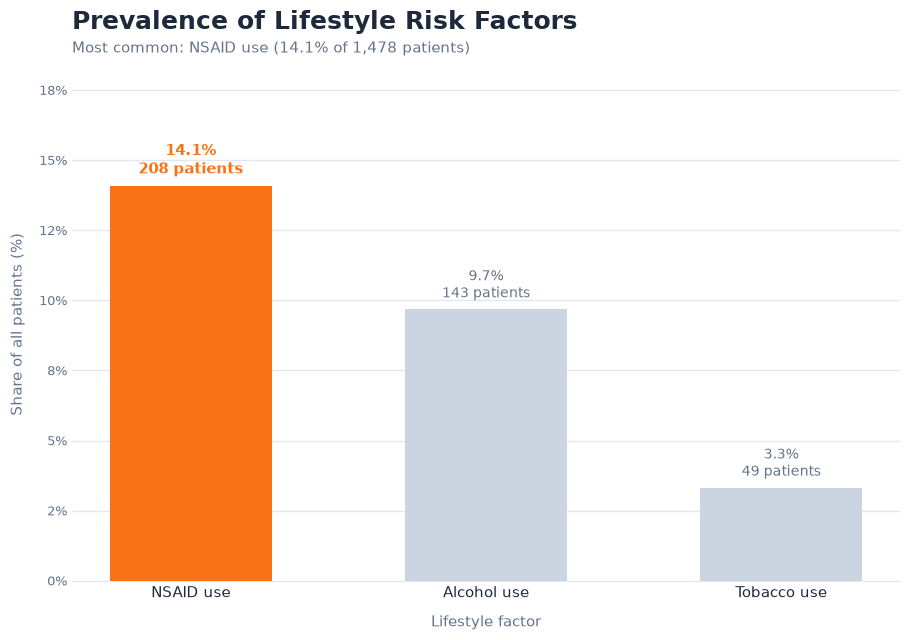

In [19]:
# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

# Readable names for the column codes (edit or add yours; unknown codes are shown as-is)
NAMES = {
    "alcohol_hx": "Alcohol use",
    "tobacco_hx": "Tobacco use",
    "nsaid_use": "NSAID use",
}

# ---------------- Prep ----------------
data = prevalence.sort_values("prevalence_pct", ascending=False).reset_index(drop=True)
labels = [NAMES.get(f, f) for f in data["lifestyle_factor"]]
pcts   = data["prevalence_pct"]
counts = data["patients"]

total_patients = df["pt_id"].nunique()
hi = 0   # sorted, so the first one is the most common

# ---------------- Plot ----------------
fig, ax = plt.subplots(figsize=(max(8, len(data) * 2.4 + 2), 6.5))
fig.patch.set_facecolor("white")

colors = [PEAK if i == hi else BASE for i in range(len(data))]
bars = ax.bar(labels, pcts, color=colors, width=0.55, zorder=3)

# Labels: prevalence on top, patient count underneath
t = ax.bar_label(bars,
                 labels=[f"{p:.1f}%\n{c:,} patients" for p, c in zip(pcts, counts)],
                 padding=5, fontsize=10, color=MUTED, linespacing=1.3)
t[hi].set_color(PEAK)
t[hi].set_fontweight("bold")
t[hi].set_fontsize(11)

# Titles
ax.set_title("Prevalence of Lifestyle Risk Factors", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03,
        f"Most common: {labels[hi]} ({pcts.iloc[hi]:.1f}% of {total_patients:,} patients)",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xlabel("Lifestyle factor", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Share of all patients (%)", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylim(0, pcts.max() * 1.3)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.tick_params(axis="x", labelsize=11, colors=TEXT, length=0)
ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

plt.tight_layout()

plt.savefig("../images/lifestyle_prevalence.png", dpi=180)
plt.show()

In [20]:
for col in lifestyle:
    print(f"\n{col.upper()}")
    print("admission duration")
    print(
        df.groupby(col)["admission_duration"]
        .agg(["count", "median", "mean"]).reset_index().round(2)
    )


ALCOHOL_HX
admission duration
  alcohol_hx  count  median   mean
0         no   1335    10.0  12.91
1        yes    143    11.0  12.26

TOBACCO_HX
admission duration
  tobacco_hx  count  median   mean
0         no   1429    10.0  12.82
1        yes     49    11.0  13.82

NSAID_USE
admission duration
  nsaid_use  count  median   mean
0        no   1270    10.0  12.40
1       yes    208    11.5  15.63


In [21]:
for col in lifestyle:
    print(f"\n{col.upper()}")

    print(
        df.groupby(col)["dead"]
        .agg(
            patients="count",
            deaths=lambda x: x.str.strip().str.lower().eq("yes").sum(),
            death_rate_pct=lambda x: round(
                x.str.strip().str.lower().eq("yes").mean() * 100, 2
            )
        ).reset_index()
    )


ALCOHOL_HX
  alcohol_hx  patients  deaths  death_rate_pct
0         no      1335     269           20.15
1        yes       143      21           14.69

TOBACCO_HX
  tobacco_hx  patients  deaths  death_rate_pct
0         no      1429     282           19.73
1        yes        49       8           16.33

NSAID_USE
  nsaid_use  patients  deaths  death_rate_pct
0        no      1270     256           20.16
1       yes       208      34           16.35


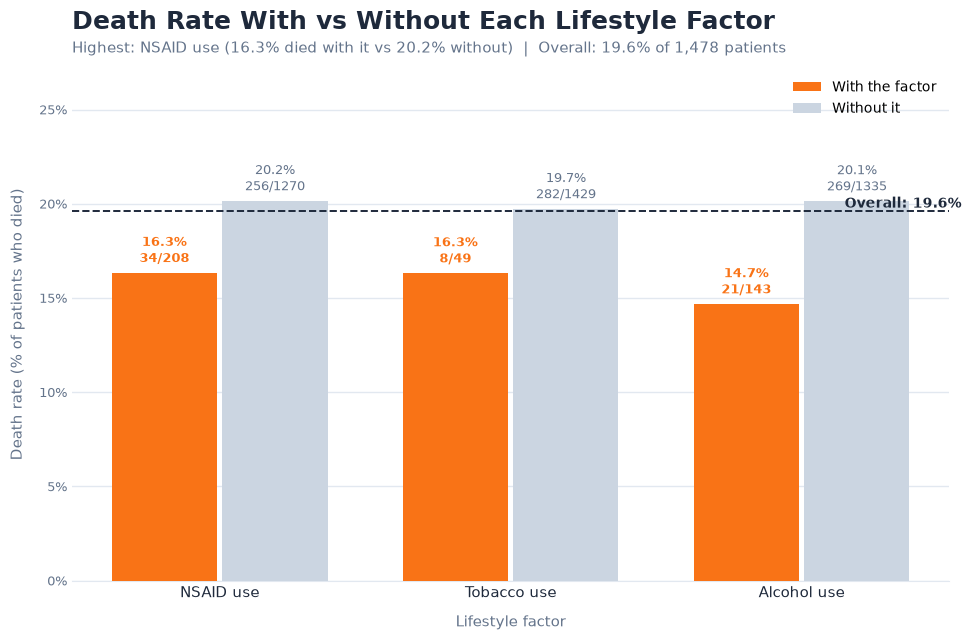

In [22]:
# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

lifestyle = ["alcohol_hx", "tobacco_hx", "nsaid_use"]   # same list as your loop
NAMES = {
    "alcohol_hx": "Alcohol use",
    "tobacco_hx": "Tobacco use",
    "nsaid_use": "NSAID use",
}
YES = ["yes", "1", "true"]

# ---------------- Prep ----------------
def is_yes(s):
    return s.astype(str).str.strip().str.lower().isin(YES)

dead    = is_yes(df["dead"])
overall = dead.mean() * 100

rows = []
for col in lifestyle:
    has = is_yes(df[col])
    r = {"factor": col}
    for key, grp in [("with", has), ("without", ~has)]:
        n, d = int(grp.sum()), int(dead[grp].sum())
        r[f"{key}_n"], r[f"{key}_dead"] = n, d
        r[f"{key}_rate"] = d / n * 100 if n else 0
    rows.append(r)

mort = (pd.DataFrame(rows)
        .sort_values("with_rate", ascending=False).reset_index(drop=True))

labels = [textwrap.fill(NAMES.get(f, f), 14) for f in mort["factor"]]

# ---------------- Plot ----------------
fig, ax = plt.subplots(figsize=(max(9, len(mort) * 2.6 + 2), 6.5))
fig.patch.set_facecolor("white")

x = np.arange(len(mort))
w = 0.38
b1 = ax.bar(x - w / 2, mort["with_rate"], width=w * 0.95, color=PEAK,
            label="With the factor", zorder=3)
b2 = ax.bar(x + w / 2, mort["without_rate"], width=w * 0.95, color=BASE,
            label="Without it", zorder=3)

ax.bar_label(b1, labels=[f"{r:.1f}%\n{d}/{n}" for r, d, n in
                         zip(mort["with_rate"], mort["with_dead"], mort["with_n"])],
             padding=4, fontsize=9.5, color=PEAK, fontweight="bold", linespacing=1.3)
ax.bar_label(b2, labels=[f"{r:.1f}%\n{d}/{n}" for r, d, n in
                         zip(mort["without_rate"], mort["without_dead"], mort["without_n"])],
             padding=4, fontsize=9.5, color=MUTED, linespacing=1.3)

# Overall death rate reference line
ax.axhline(overall, color=TEXT, linestyle="--", linewidth=1.4, zorder=4)
ax.text(len(mort) - 0.45, overall, f"Overall: {overall:.1f}%", ha="right", va="bottom",
        fontsize=10, color=TEXT, fontweight="bold")

# Titles
top = mort.iloc[0]
top_name = NAMES.get(top["factor"], top["factor"])
ax.set_title("Death Rate With vs Without Each Lifestyle Factor", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03,
        f"Highest: {top_name} ({top['with_rate']:.1f}% died with it vs "
        f"{top['without_rate']:.1f}% without)  |  Overall: {overall:.1f}% of {len(df):,} patients",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11, color=TEXT)
ax.set_xlabel("Lifestyle factor", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Death rate (% of patients who died)", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylim(0, max(mort["with_rate"].max(), mort["without_rate"].max()) * 1.35)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.tick_params(axis="x", length=0)
ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)
ax.legend(frameon=False, loc="upper right", fontsize=10)

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

plt.tight_layout()

plt.savefig("../images/death_rate_by_lifestyle.png", dpi=180)
plt.show()